# Assignment 2: Build a CNN for image recognition.

## Due Date:  Oct 28, 11:59PM

### Name: [Tristan Shabbick]


## Introduction:

1. In this assignment, you will build Convolutional Neural Network to classify CIFAR-10 Images.
2. You can directly load dataset from many deep learning packages.
3. You can use any deep learning packages such as pytorch, keras or tensorflow for this assignment.

## Requirements:

1. You need to load cifar 10 data and split the entire training dataset into training and validation.
2. You will implement a CNN model to classify cifar 10 images with provided structure.
3. You need to plot the training and validation accuracy or loss obtained from above step.
4. Then you can use tuned parameters to train using the entire training dataset.
5. You should report the testing accuracy using the model with complete data.
6. You may try to change the structure (e.g, add BN layer or dropout layer,...) and analyze your findings.

## Google Colab

- If you do not have GPU, the training of a CNN can be slow. Google Colab is a good option.

## Batch Normalization (BN)

### Background:

- Batch Normalization is a technique to speed up training and help make the model more stable.
- In simple words, batch normalization is just another network layer that gets inserted between a hidden layer and the next hidden layer. Its job is to take the outputs from the first hidden layer and normalize them before passing them on as the input of the next hidden layer.

- For more detailed information, you may refer to the original paper: https://arxiv.org/pdf/1502.03167.pdf.

### BN Algorithm:

- Input: Values of $x$ over a mini-batch: $\mathbf{B}$ = $\{x_1,..., x_m\};$
- Output: $\{y_i = BN_{\gamma,\beta}(x_i)\}$, $\gamma, \beta$ are learnable parameters

Normalization of the Input:
$$\mu_{\mathbf{B}} = \frac{1}{m}\sum_{i=1}^m x_i$$
$$\sigma_{\mathbf{B}}^2 = \frac{1}{m}\sum_{i=1}^m (x_i - \mu_{\mathbf{B}})^2$$
$$\hat{x_i} = \frac{x_i - \mu_{\mathbf{B}}}{\sqrt{\sigma_{\mathbf{B}}}^2 + \epsilon}$$
Re-scaling and offsetting:
$$y_i = \gamma \hat{x_i} + \beta = BN_{\gamma,\beta}(x_i)$$


### Advantages of BN:
1. Improves gradient flow through the network.
2. Allows use of saturating nonlinearities and higher learning rates.
3. Makes weights easier to initialize.
4. Act as a form of regularization and may reduce the need for dropout.

### Implementation:

- The batch normalization layer has already been implemented in many packages. You may simply call the function to build the layer.
- The location of BN layer: Please make sure ```BatchNormalization``` is between a ```Conv```/```Dense``` layer and an ```activation``` layer.

## 1. Data preparation

### 1.1. Load data


In [ ]:
# Load Cifar-10 Data
# This is just an example, you may load dataset from other packages.
import keras
import numpy as np
from sklearn.model_selection import train_test_split # from Assignment 1

# for building the CNN Model itself:
from keras import models  
from keras import layers
from keras import optimizers

(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

# Lecture 5 page 59
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print('shape of x_train: ' + str(x_train.shape))
print('shape of y_train: ' + str(y_train.shape))
print('shape of x_test: ' + str(x_test.shape))
print('shape of y_test: ' + str(y_test.shape))
print('number of classes: ' + str(np.max(y_train) - np.min(y_train) + 1))

learning_rate = 0.001 # Explanation provided in Section 2 

shape of x_train: (50000, 32, 32, 3)
shape of y_train: (50000, 1)
shape of x_test: (10000, 32, 32, 3)
shape of y_test: (10000, 1)
number of classes: 10


### 1.2. One-hot encode the labels (5 points)

In the input, a label is a scalar in $\{0, 1, \cdots , 9\}$. One-hot encoding transforms such a scalar to a $10$-dim vector. E.g., a scalar ```y_train[j]=3``` is transformed to the vector ```y_train_vec[j]=[0, 0, 0, 1, 0, 0, 0, 0, 0, 0]```.

1. Implement a function ```to_one_hot``` that transforms an $n\times 1$ array to a $n\times 10$ matrix.

2. Apply the function to ```y_train``` and ```y_test```.

In [2]:
def to_one_hot(y, num_class=10): # Implementation is largely from Lecture 5, page 60 
    results = np.zeros((len(y), num_class))
    for i, label in enumerate(y):
        results[i, int(label[0])] = 1
    return results

# apply the function to y_train and y_test
y_train_vec = to_one_hot(y_train)
y_test_vec = to_one_hot(y_test)

print('Shape of y_train_vec: ' + str(y_train_vec.shape))
print('Shape of y_test_vec: ' + str(y_test_vec.shape))

print(y_train[0])
print(y_train_vec[0])

Shape of y_train_vec: (50000, 10)
Shape of y_test_vec: (10000, 10)
[6]
[0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]


#### Remark: the outputs should be
* Shape of y_train_vec: (50000, 10)
* Shape of y_test_vec: (10000, 10)
* [6]
* [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]

### 1.3. Randomly partition the training set to training and validation sets (5 points)

Randomly partition the 50K training samples to 2 sets: 
* a training set containing 40K samples: x_tr, y_tr
* a validation set containing 10K samples: x_val, y_val


In [3]:
x_tr, x_val, y_tr, y_val = train_test_split(x_train, y_train_vec, test_size=10000, random_state=1) 
# Like in Assignment 1, random_state=1 is used as the seed for reproducibility, 1 specifically is based on rand(3)/random(3) defaulting to 1 if no seed argument is specified.

print('Shape of x_tr: ' + str(x_tr.shape))
print('Shape of y_tr: ' + str(y_tr.shape))
print('Shape of x_val: ' + str(x_val.shape))
print('Shape of y_val: ' + str(y_val.shape))

Shape of x_tr: (40000, 32, 32, 3)
Shape of y_tr: (40000, 10)
Shape of x_val: (10000, 32, 32, 3)
Shape of y_val: (10000, 10)


## 2. Build a CNN and tune its hyper-parameters (50 points)

- Build a convolutional neural network model using the below structure:

- It should have a structure of: Conv - ReLU - Max Pool - ConV - ReLU - Max Pool - Dense - ReLU - Dense - Softmax

- In the graph, 3@32x32 means the dimension of input image, 32@30x30 means it has 32 filters and the dimension now becomes 30x30 after the convolution.
- All convolutional layers (Conv) should have stride = 1 and no padding.
- Max Pooling has a pool size of 2 by 2.




<img src="network.PNG"/>


- You may use the validation data to tune the hyper-parameters (e.g., learning rate, and optimization algorithm)
- Do NOT use test data for hyper-parameter tuning!!!
- Try to achieve a validation accuracy as high as possible.

In [ ]:
# Build the model
model = models.Sequential() 
# model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3))) <- contrary to what the lecture notes suggest, this gives a runtime "UserWarning", which reccomends we feed the input layer on it's own line, so lets do that:
model.add(layers.Input(shape=(32, 32, 3)))
model.add(layers.Conv2D(32, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (4, 4), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Flatten())
model.add(layers.Dense(256, activation='relu'))
model.add(layers.Dense(10, activation='softmax'))

model.summary() # confirm we modeled the architecture correctly based on the network.PNG above

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 12, 12, 64)     │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 626,378 (2.39 MB)

 Trainable params: 626,378 (2.39 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Define model optimizer and loss function
model.compile(optimizers.RMSprop(learning_rate=learning_rate), loss='categorical_crossentropy', metrics=['accuracy']) # from Lecture 5 page 69
# learning rates tested: 0.001, 0.0001; see below.

# The following warning is thrown on python 3.11 with the most recent version (2.22 or so) of tensorflow: 
# WARNING:tensorflow:TensorFlow GPU support is not available on native Windows for TensorFlow >= 2.11. Even if CUDA/cuDNN are installed, GPU will not be used. Please use WSL2 or the TensorFlow-DirectML plugin.
# See the next cell for more information.

In [ ]:
# Train the model and store model parameters/loss values
history = model.fit(x_tr, y_tr, batch_size=128, epochs=50, validation_data=(x_val, y_val)) # from Lecture 5 page 70

# In the interest of saving a ton of time while tuning hyperparameters, instead of waiting for the runs to complete on my CPU, I placed the following code on Stevens' High Performance Compute cluster, JARVIS, and ran them on the H100/200 nodes to make the training go a couple of orders of magnitude faster.
# The code that ran on such, giving us the fixed batch_size of 128 and learning_rate (defined at the top for easy re-use):
#
# configs = [(0.0001, 128), (0.001, 128), (0.0001, 32), (0.001, 32)]
# tuning = {}

# for lr, bs in configs:
#     m = keras.models.clone_model(model) # same architecture but with new weights
#     m.compile(optimizers.RMSprop(learning_rate=lr), loss='categorical_crossentropy', metrics=['accuracy'])
#     h = m.fit(x_tr, y_tr, batch_size=bs, epochs=50, validation_data=(x_val, y_val), verbose=0)
#     tuning[(lr, bs)] = h
#     best = int(np.argmin(h.history['val_loss']))
#     print(f'lr {lr} | batch {bs} | best epoch: {best + 1} | val_loss: {round(h.history["val_loss"][best], 4)} | val_acc: {round(h.history["val_accuracy"][best], 4)}')
# 
# This produced (at the time):
# lr 0.0001 | batch 128 | best epoch: 50 | val_loss: 0.907 | val_acc: 0.6908
# lr 0.001 | batch 128 | best epoch: 6 | val_loss: 0.8624 | val_acc: 0.7002
# lr 0.0001 | batch 32 | best epoch: 26 | val_loss: 0.867 | val_acc: 0.7052
# lr 0.001 | batch 32 | best epoch: 4 | val_loss: 0.8754 | val_acc: 0.6987
# Where we can see that a learning rate of 0.001 with a batch size of 128 produced the lowest validation loss, although this appears to be within variance of a 10x lower learning rate with a batch size of 32. 
# Note that while batch size and learning rate are fixed in accordance with this data, the epoch with the lowest validation loss is selected each time the program is ran (which was done at the time to make testing easier; this occurs below) 


Epoch 1/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.3975 - loss: 1.6878 - val_accuracy: 0.4899 - val_loss: 1.4079
Epoch 2/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.5508 - loss: 1.2769 - val_accuracy: 0.5323 - val_loss: 1.3952
Epoch 3/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.6228 - loss: 1.0837 - val_accuracy: 0.5751 - val_loss: 1.1938
Epoch 4/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.6694 - loss: 0.9544 - val_accuracy: 0.6171 - val_loss: 1.1065
Epoch 5/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7066 - loss: 0.8457 - val_accuracy: 0.6831 - val_loss: 0.9160
Epoch 6/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7393 - loss: 0.7493 - val_accuracy: 0.6381 - val_loss: 1.0506
Epoch 7/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7730 - loss: 0.6588 - val_accuracy: 0.6858 - val_loss: 0.9131
Epoch 8/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8030 - loss: 0.5744 - val_accu

## 3. Plot the training and validation loss curve versus epochs. (5 points)

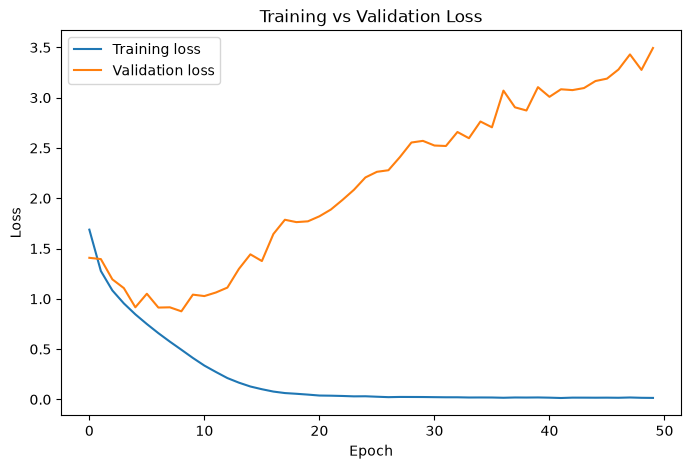

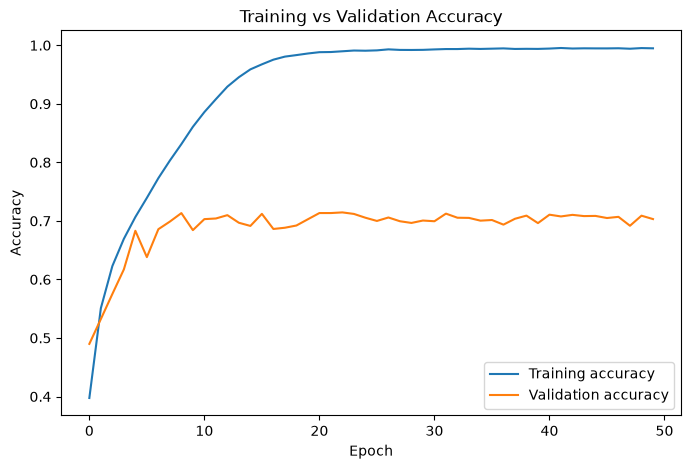

In [7]:
# Plot the loss curve
import matplotlib.pyplot as plt
%matplotlib inline

train_loss = history.history['loss']
val_loss = history.history['val_loss']
train_acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

plt.figure(figsize=(8, 5))
plt.plot(train_loss, label='Training loss')
plt.plot(val_loss, label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.show()
# Plot showcases a clear pattern of overfitting 

# This section doesn't specify/require it, but a Training vs Validation Accuracy Plot is useful and nice to look at as well 
plt.figure(figsize=(8, 5))
plt.plot(train_acc, label='Training accuracy')
plt.plot(val_acc, label='Validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.show()



## 4. Train (again) and evaluate the model (5 points)

- To this end, you have found the "best" hyper-parameters. 
- Now, fix the hyper-parameters and train the network on the entire training set (all the 50K training samples)
- Evaluate your model on the test set.

### Train the model on the entire training set



In [ ]:
#<Compile your model again (using the same hyper-parameters you tuned above)>
model = keras.models.clone_model(model) # same architecture but with new weights

model.compile(optimizers.RMSprop(learning_rate=learning_rate), loss='categorical_crossentropy', metrics=['accuracy']) # from Lecture 5 page 69

In [ ]:
#<Train your model on the entire training set (50K samples)>
best_epochs = int(np.argmin(history.history['val_loss'])) + 1 # finds the epoch with the lowest validation loss
print('Training on all 50K training samples for', best_epochs, 'epochs')

history_full = model.fit(x_train, y_train_vec, batch_size=128, epochs=best_epochs)

Training on all 50K training samples for 9 epochs
Epoch 1/9
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.4152 - loss: 1.6369
Epoch 2/9
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.5780 - loss: 1.2053
Epoch 3/9
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6496 - loss: 1.0123
Epoch 4/9
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6978 - loss: 0.8759
Epoch 5/9
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.7357 - loss: 0.7691
Epoch 6/9
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.7684 - loss: 0.6719
Epoch 7/9
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.7983 - loss: 0.5832
Epoch 8/9
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8301 - loss: 0.4925
Epoch 9/9
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8583 - loss: 0.4117


## 5. Evaluate the model on the test set (5 points)

Do NOT used the test set until now. Make sure that your model parameters and hyper-parameters are independent of the test set.

In [10]:
# Evaluate your model performance (testing accuracy) on testing data.
test_loss, test_acc = model.evaluate(x_test, y_test_vec)
print('Test accuracy:', test_acc)
print('Test loss:', test_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7138 - loss: 0.9284
Test accuracy: 0.7138000130653381
Test loss: 0.9284342527389526


## 6. Building model with new structure (25 points)
- In this section, you can build your model with adding new layers (e.g, BN layer or dropout layer, ...)
- If you want to regularize a ```Conv/Dense layer```, you should place a ```Dropout layer``` before the ```Conv/Dense layer```.
- You can try to compare their loss curve and testing accuracy and analyze your findings.
- You need to try at lease two different structures.

In [11]:
print("Beginning Batch Normalization Model Training")
model_bn = models.Sequential()
model_bn.add(layers.Input(shape=(32, 32, 3)))

model_bn.add(layers.Conv2D(32, (3, 3)))
model_bn.add(layers.BatchNormalization())
model_bn.add(layers.Activation('relu'))
model_bn.add(layers.MaxPooling2D((2, 2)))

model_bn.add(layers.Conv2D(64, (4, 4)))
model_bn.add(layers.BatchNormalization())
model_bn.add(layers.Activation('relu'))
model_bn.add(layers.MaxPooling2D((2, 2)))

model_bn.add(layers.Flatten())
model_bn.add(layers.Dense(256))
model_bn.add(layers.BatchNormalization())
model_bn.add(layers.Activation('relu'))
model_bn.add(layers.Dense(10, activation='softmax'))

model_bn.compile(optimizers.RMSprop(learning_rate=learning_rate), loss='categorical_crossentropy', metrics=['accuracy'])
history_bn = model_bn.fit(x_tr, y_tr, batch_size=128, epochs=50, validation_data=(x_val, y_val))

print("Beginning dropout model training 1")
model_do = models.Sequential()
model_do.add(layers.Input(shape=(32, 32, 3)))
model_do.add(layers.Conv2D(32, (3, 3), activation='relu'))
model_do.add(layers.MaxPooling2D((2, 2)))
model_do.add(layers.Conv2D(64, (4, 4), activation='relu'))
model_do.add(layers.MaxPooling2D((2, 2)))
model_do.add(layers.Flatten())
model_do.add(layers.Dropout(0.5))
model_do.add(layers.Dense(256, activation='relu'))
model_do.add(layers.Dropout(0.5))
model_do.add(layers.Dense(10, activation='softmax'))

model_do.compile(optimizers.RMSprop(learning_rate=learning_rate), loss='categorical_crossentropy', metrics=['accuracy'])

history_do = model_do.fit(x_tr, y_tr, batch_size=128, epochs=50, validation_data=(x_val, y_val))

print("Beginning dropout model training 2")
model_do2 = models.Sequential()
model_do2.add(layers.Input(shape=(32, 32, 3)))
model_do2.add(layers.Conv2D(32, (3, 3), activation='relu'))
model_do2.add(layers.MaxPooling2D((2, 2)))
model_do2.add(layers.Dropout(0.25))
model_do2.add(layers.Conv2D(64, (4, 4), activation='relu'))
model_do2.add(layers.MaxPooling2D((2, 2)))
model_do2.add(layers.Flatten())
model_do2.add(layers.Dropout(0.5))
model_do2.add(layers.Dense(256, activation='relu'))
model_do2.add(layers.Dense(10, activation='softmax'))

model_do2.compile(optimizers.RMSprop(learning_rate=learning_rate), loss='categorical_crossentropy', metrics=['accuracy'])
    
history_do2 = model_do2.fit(x_tr, y_tr, batch_size=128, epochs=50, validation_data=(x_val, y_val))

Beginning Batch Normalization Model Training
Epoch 1/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.5746 - loss: 1.1998 - val_accuracy: 0.2344 - val_loss: 2.6918
Epoch 2/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.7144 - loss: 0.8269 - val_accuracy: 0.6221 - val_loss: 1.0883
Epoch 3/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.7742 - loss: 0.6561 - val_accuracy: 0.6202 - val_loss: 1.1156
Epoch 4/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.8235 - loss: 0.5202 - val_accuracy: 0.6675 - val_loss: 1.0357
Epoch 5/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.8640 - loss: 0.4076 - val_accuracy: 0.6405 - val_loss: 1.1676
Epoch 6/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.8986 - loss: 0.3126 - val_accuracy: 0.6480 - val_loss: 1.1701
Epoch 7/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.9270 - loss: 0.2346 - val_accuracy: 0.6887 - val_loss: 1.0911
Epoch 8/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step

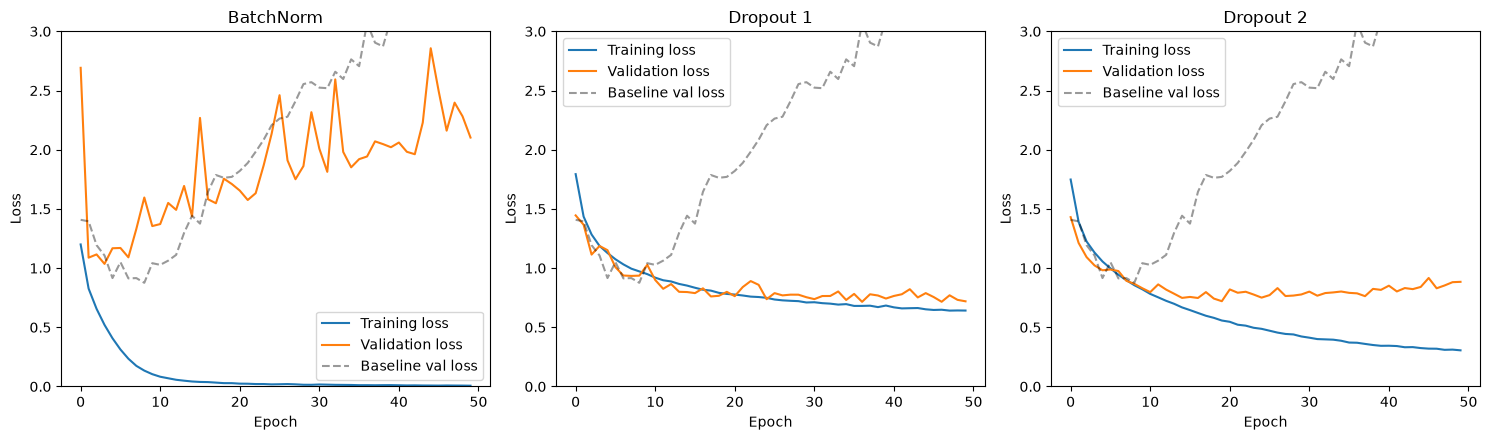

BatchNorm | epochs: 4 | test_acc: 0.5982000231742859 | test_loss: 1.2591620683670044
Dropout 1 | epochs: 37 | test_acc: 0.7613000273704529 | test_loss: 0.7295571565628052
Dropout 2 | epochs: 20 | test_acc: 0.754800021648407 | test_loss: 0.7368575930595398


In [ ]:
new_models = [('BatchNorm', history_bn), ('Dropout 1', history_do), ('Dropout 2', history_do2)]

plt.figure(figsize=(15, 4.5))
for k, (name, h) in enumerate(new_models):
    plt.subplot(1, 3, k + 1)
    plt.plot(h.history['loss'], label='Training loss')
    plt.plot(h.history['val_loss'], label='Validation loss')
    plt.plot(history.history['val_loss'], 'k--', alpha=0.4, label='Baseline val loss')
    plt.ylim(0, 3.0)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title(name)
    plt.legend()
plt.tight_layout()
plt.show()

def retrain_and_test(model_template, hist, name):
    best = int(np.argmin(hist.history['val_loss'])) + 1

    m = keras.models.clone_model(model_template)
    m.compile(optimizers.RMSprop(learning_rate=learning_rate), loss='categorical_crossentropy', metrics=['accuracy'])
    m.fit(x_train, y_train_vec, batch_size=128, epochs=best, verbose=0) # verbose=0 supresses the output log as is present in cells above

    test_loss, test_acc = m.evaluate(x_test, y_test_vec, verbose=0)

    print(f'{name} | epochs: {best} | test_acc: {test_acc} | test_loss: {test_loss}')

retrain_and_test(model_bn, history_bn, 'BatchNorm')
retrain_and_test(model_do, history_do, 'Dropout 1')
retrain_and_test(model_do2, history_do2, 'Dropout 2')

# Analysis of the 3 tested architectures (single run with unseeded weights, so exact numbers shift slightly between runs):
# Test accuracy after retraining on all 50K, with the epoch count chosen at the lowest validation loss: baseline 71.38% (9 epochs), BatchNorm 59.82% (4 epochs), Dropout 1 76.13% (37 epochs), Dropout 2 75.48% (20 epochs).
# Dropout 1 (0.5 before both Dense layers) performs best: highest test accuracy, lowest validation loss (0.715) and highest validation accuracy (76.6%). Its training accuracy at epoch 50 (78.5%) is close to its validation accuracy (76.1%), so there is almost no overfitting.
# Dropout 2 (0.25 before the second Conv, 0.5 before the first Dense) is close (75.48% test) but overfits more (89.4% train vs 75.0% validation at epoch 50). 
# Its dropout is earlier but lighter, and the dense layers hold most of the parameters (~590K of 626K), which is why Dropout 1 regularizes more. 
# The two dropout models differ by under 1 point in test accuracy and validation loss, which note is well within run to run variance.
# BatchNorm provides no overfitting relief: 99.9% train accuracy at epoch 50 and validation loss climbing to 2.10. Its best validation accuracy (71.4%, epoch 36) is about the same as the baseline's (71.5%). 
# Its 59.82% test score likely comes from retraining with the epoch with the lowest validation loss. Its validation loss bottoms out at epoch 4, when its validation accuracy is only 66.8%, so it was probably undertrained.
# Both dropout models beat the baseline by about 4-5 points of test accuracy. This architecture seems to top out around 75-76% accuracy, with anything higher likely needing a complete re-structure of the CNN, which is beyond the scope of this assignment.